# Chapitre 8 - Exercices 8.7 à 8.11

Ces exercices portent sur la **synthèse vérifiée** (cours 2) et le **traitement** des
données (cours 3) :

- **8.7** : synthèse vérifiable de raisonnements avec Qwen2.5-0.5B : filtre par la
  réponse, auto-cohérence, coût par exemple gardé (mini-lab et calcul) ;
- **8.8** : un juge IA pour les données de préférence et son biais de position, avec la
  parade de NVIDIA (mini-lab) ;
- **8.9** : effondrement de modèle : demi-vie de la variance, point fixe avec données
  réelles, disparition des événements rares (calcul et simulation) ;
- **8.10** : dimensionner MinHash + LSH pour un milliard de documents (calcul et
  vérification) ;
- **8.11** : mise au format SFT : conversation multi-tours, masque de perte, bogues de
  template et d'espaces (mini-lab).

Les exercices 8.7 et 8.8 utilisent le GPU (Qwen2.5-0.5B et 1,5B, chargés l'un après
l'autre) ; les autres tournent sur CPU.

In [1]:
import warnings
from math import comb, log

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from aie import ch08_donnees as d8
from aie import llm
from aie.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                          annotate_bars, finish, set_style, subtitle)

warnings.filterwarnings("ignore")
set_style()
rng = np.random.default_rng(0)


def log_lisible(ax, axes="y"):
    """Graduations log au format décimal simple (sans exposants mathtext)."""
    from matplotlib.ticker import FuncFormatter, NullFormatter
    for a in axes:
        axis = ax.yaxis if a == "y" else ax.xaxis
        axis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
        axis.set_minor_formatter(NullFormatter())

## Exercice 8.7 : Synthèse vérifiable de raisonnements

**Énoncé.** On veut constituer un jeu de raisonnements pas à pas (CoT) pour des
problèmes arithmétiques, en faisant écrire les raisonnements par Qwen2.5-0.5B.

1. Générer un raisonnement glouton pour 16 problèmes produits par gabarit et ne garder
   que ceux dont la réponse finale est juste. Quel est le taux d'acceptation $p$ ?
2. **Auto-cohérence** : tirer 5 raisonnements à température 0,7 par problème. (a) Le
   vote majoritaire des réponses est-il plus souvent juste que le glouton ? (b) Sans
   vérité terrain, on garde un problème si au moins 3 réponses sur 5 concordent : quelle
   est la **précision** de ce filtre ?
3. Combien de générations faut-il pour obtenir 10 000 raisonnements vérifiés, et
   combien cela coûte-t-il si une génération de 200 tokens coûte $2 \times 10^{-4}$
   dollar ?

**Rappels.** Cours 2, section 6.1 et section *Data verification* du livre : on
synthétise d'abord ce que l'on sait vérifier ; la correction fonctionnelle (réponse
connue, exécution de tests) filtre les exemples. Une réponse finale juste n'implique pas
un raisonnement juste.

In [2]:
pbs = d8.make_word_problems(16, seed=7)
consigne = " Raisonne étape par étape puis termine par « Réponse : <nombre> »."
glouton = [d8.extract_number(llm.chat(p["question"] + consigne, llm.SMALL, max_new_tokens=220)) for p in pbs]
tirages = [[d8.extract_number(llm.chat(p["question"] + consigne, llm.SMALL, max_new_tokens=220,
                                       temperature=0.7, seed=100 + k)) for k in range(5)] for p in pbs]
llm.free_gpu()

lignes = []
for p, g, t in zip(pbs, glouton, tirages):
    vals = [v for v in t if v is not None]
    maj, nmaj = (pd.Series(vals).value_counts().index[0], pd.Series(vals).value_counts().iloc[0]) if vals else (None, 0)
    lignes.append({"attendu": p["answer"], "glouton": g, "tirages": t, "vote": maj, "accord (sur 5)": nmaj,
                   "glouton juste": g == p["answer"], "vote juste": maj == p["answer"],
                   "tirages justes": sum(v == p["answer"] for v in t)})
tab = pd.DataFrame(lignes)
tab[["attendu", "glouton", "tirages", "vote", "accord (sur 5)"]].head(8)

,attendu,glouton,tirages,vote,accord (sur 5)
0,26,-26,"[26, 26, 0, 3, 204]",26,2
1,143,143,"[133, 17, 46, 143, 396]",133,1
2,51,77,"[51, 43, 55, 47, 43]",43,2
3,25,26,"[39, 43, 15, 25, 25]",25,2
4,51,51,"[111, 51, 68, 18, 57]",111,1
5,96,96,"[138, 96, 5, 78, 36]",138,1
6,35,16,"[6, 53, 10, 65, None]",6,1
7,190,500,"[60, 190, 20, 61, 4]",60,1


**Solution.**

1. Taux d'acceptation (glouton) : p = 0.44
   Taux de réussite d'un tirage à T = 0,7 : 0.31
2a. Vote majoritaire sur 5 tirages : 0.50
2b. Filtre « au moins 3/5 concordent » : garde 19% des problèmes, précision 1.00


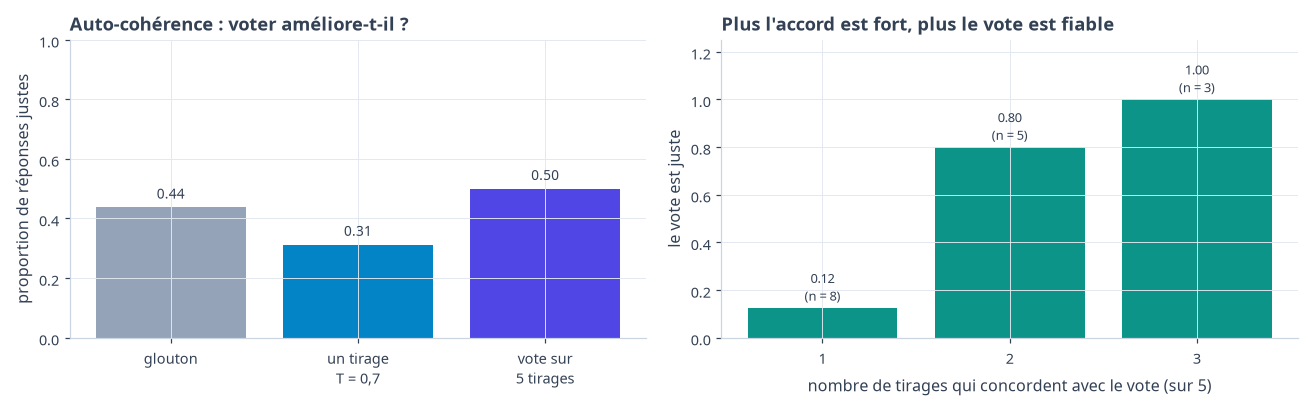

In [3]:
p_glouton = tab["glouton juste"].mean()
p_tirage = tab["tirages justes"].sum() / (5 * len(tab))
p_vote = tab["vote juste"].mean()
garde = tab["accord (sur 5)"] >= 3
precision = tab.loc[garde, "vote juste"].mean() if garde.any() else np.nan
print(f"1. Taux d'acceptation (glouton) : p = {p_glouton:.2f}")
print(f"   Taux de réussite d'un tirage à T = 0,7 : {p_tirage:.2f}")
print(f"2a. Vote majoritaire sur 5 tirages : {p_vote:.2f}")
print(f"2b. Filtre « au moins 3/5 concordent » : garde {garde.mean():.0%} des problèmes, précision {precision:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
ax.bar(["glouton", "un tirage\nT = 0,7", "vote sur\n5 tirages"], [p_glouton, p_tirage, p_vote], color=[GRAY, SKY, INDIGO])
annotate_bars(ax, "{:.2f}")
ax.set_ylim(0, 1)
ax.set_ylabel("proportion de réponses justes")
ax.set_title("Auto-cohérence : voter améliore-t-il ?")
ax = axes[1]
acc_par_accord = tab.groupby("accord (sur 5)")["vote juste"].agg(["mean", "size"])
ax.bar(acc_par_accord.index.astype(str), acc_par_accord["mean"], color=TEAL)
for i, (m_, n_) in enumerate(acc_par_accord.values):
    ax.text(i, m_ + 0.03, f"{m_:.2f}\n(n = {int(n_)})", ha="center", fontsize=8.5)
ax.set_ylim(0, 1.25)
ax.set_xlabel("nombre de tirages qui concordent avec le vote (sur 5)")
ax.set_ylabel("le vote est juste")
ax.set_title("Plus l'accord est fort, plus le vote est fiable")
finish(fig)
plt.show()

**Interprétation (questions 1 et 2).** Le petit modèle se trompe souvent : le filtre par
la réponse connue écarte une part importante des raisonnements. Le vote sur plusieurs
tirages est en général au moins aussi bon que le glouton (les erreurs de calcul sont
en partie aléatoires et se compensent), et le **degré d'accord** entre tirages est un
indicateur de fiabilité utilisable **sans vérité terrain** : la proportion de votes
justes croît avec le nombre de tirages concordants, et un vote soutenu par un seul
tirage n'est presque jamais fiable. Avec 16 problèmes, ces proportions restent très
incertaines (un problème vaut 6 points de pourcentage) ; il faudrait quelques centaines
de problèmes pour conclure.

**Question 3.** Le nombre de générations par exemple gardé suit une loi géométrique de
moyenne $1/p$ : pour $N$ exemples vérifiés, il faut en moyenne $N/p$ générations. Avec
l'auto-cohérence, chaque problème coûte 5 générations, et l'on garde une fraction $g$
des problèmes (ceux où l'accord est suffisant), soit $5N/g$ générations.

In [4]:
N_ = 10_000
cout_gen = 2e-4
scenarios = {"glouton + vérité terrain": 1 / p_glouton,
             "5 tirages + filtre d'accord (sans vérité)": 5 / garde.mean()}
for nom, k in scenarios.items():
    print(f"{nom:42s} : {N_ * k:>9,.0f} générations, {N_ * k * cout_gen:>6,.1f} dollars".replace(",", " "))

glouton + vérité terrain                   :    22 857 générations     4.6 dollars
5 tirages + filtre d'accord (sans vérité)  :   266 667 générations    53.3 dollars


Même à faible coût unitaire, la génération vérifiée n'est pas gratuite, et
l'auto-cohérence multiplie le coût. Mais elle fournit une vérification là où la réponse
n'est pas connue. Dernier point : le filtrage **biaise** le jeu vers les problèmes que
le modèle réussit déjà, c'est-à-dire les plus faciles. On surveille donc la répartition
par gabarit (ou par difficulté) des exemples gardés, et l'on complète les zones faibles
par un générateur plus fort ou par des humains.

> **À retenir.** Générer, vérifier, filtrer : le coût par exemple gardé vaut
> $1/p$ générations. L'auto-cohérence (vote sur plusieurs tirages) améliore souvent la
> réponse et fournit, via le taux d'accord, un signal de fiabilité sans vérité terrain.
> Le filtrage biaise vers les cas faciles : surveiller la couverture après filtrage.

## Exercice 8.8 : Juge IA et biais de position

**Énoncé.** Pour fabriquer des données de préférence (instruction, réponse gagnante,
réponse perdante), on demande à un modèle de choisir la meilleure de deux réponses. Le
livre rapporte que NVIDIA pose la question **deux fois**, en inversant l'ordre, et ne
garde un triplet que si le juge désigne le même gagnant les deux fois.

1. Construire 18 paires (bonne réponse humaine, réponse dégradée) à partir des données
   du cours 3. Trois dégradations : réponse tronquée, réponse vague, réponse à une autre
   question.
2. Faire juger chaque paire dans les deux ordres par Qwen2.5-1.5B puis par
   Qwen2.5-0.5B, en lisant la probabilité des tokens « A » et « B ». Mesurer
   l'exactitude, la proportion de « A » et le taux de cohérence.
3. Quelle est l'exactitude des paires gardées par le filtre de cohérence ? Combien en
   perd-on ?

**Rappels.** Chapitre 3 (juges IA) et cours 2 : un juge a des biais, dont le **biais de
première position** (préférer l'option présentée en premier). La section
*AI-Powered Data Synthesis* du livre décrit la parade de NVIDIA.

In [5]:
fr = [p for p in d8.BASE_PAIRS if p[0] == "fr"]
paires = []
for k in range(18):
    _, _, q, bonne = fr[k % len(fr)]
    typ = ["tronquée", "vague", "hors sujet"][k % 3]
    if typ == "tronquée":
        mauvaise = " ".join(bonne.split()[:4]) + "..."
    elif typ == "vague":
        mauvaise = "C'est une bonne question. Cela dépend de nombreux facteurs, il faut voir au cas par cas."
    else:
        mauvaise = fr[(k + 7) % len(fr)][3]
    paires.append((q, bonne, mauvaise, typ))


def proba_A(question, rep_a, rep_b, model_id):
    """Probabilité (renormalisée sur {A, B}) que le juge réponde « A »."""
    import torch

    tok, model = llm.load(model_id)
    prompt = (f"Question : {question}\n\nRéponse A : {rep_a}\n\nRéponse B : {rep_b}\n\n"
              "Quelle réponse est la plus utile et la plus correcte ? Réponds uniquement par la lettre A ou B.")
    ids = tok.apply_chat_template([{"role": "user", "content": prompt}], add_generation_prompt=True,
                                  return_tensors="pt", return_dict=True).to(model.device)
    with torch.no_grad():
        logits = model(**ids).logits[0, -1].float()
    ia, ib = tok.convert_tokens_to_ids("A"), tok.convert_tokens_to_ids("B")
    return float(torch.softmax(logits[[ia, ib]], -1)[0])


resultats = {}
for mid in (llm.MEDIUM, llm.SMALL):
    rows = []
    for q, bonne, mauvaise, typ in paires:
        pa1 = proba_A(q, bonne, mauvaise, mid)   # bonne réponse en position A
        pa2 = proba_A(q, mauvaise, bonne, mid)   # bonne réponse en position B
        rows.append({"type": typ, "juste (bonne en A)": pa1 > 0.5, "juste (bonne en B)": pa2 < 0.5,
                     "choix A (1)": pa1 > 0.5, "choix A (2)": pa2 > 0.5})
    df = pd.DataFrame(rows)
    df["cohérent"] = df["choix A (1)"] != df["choix A (2)"]   # même gagnant dans les deux ordres
    df["juste et cohérent"] = df["juste (bonne en A)"] & df["juste (bonne en B)"]
    resultats[mid] = df
    llm.free_gpu()

synthese = pd.DataFrame({
    nom: {"exactitude (bonne en A)": df["juste (bonne en A)"].mean(),
          "exactitude (bonne en B)": df["juste (bonne en B)"].mean(),
          "proportion de « A »": (df["choix A (1)"].sum() + df["choix A (2)"].sum()) / (2 * len(df)),
          "taux de cohérence": df["cohérent"].mean(),
          "exactitude des paires gardées": df.loc[df["cohérent"], "juste et cohérent"].mean() if df["cohérent"].any() else np.nan}
    for nom, df in [("Qwen2.5-1.5B", resultats[llm.MEDIUM]), ("Qwen2.5-0.5B", resultats[llm.SMALL])]
}).T
synthese.round(2)

,exactitude (bonne en A),exactitude (bonne en B),proportion de « A »,taux de cohérence,exactitude des paires gardées
Qwen2.5-1.5B,1.0,0.83,0.58,0.83,1.0
Qwen2.5-0.5B,1.0,0.00,1.00,0.00,NaN


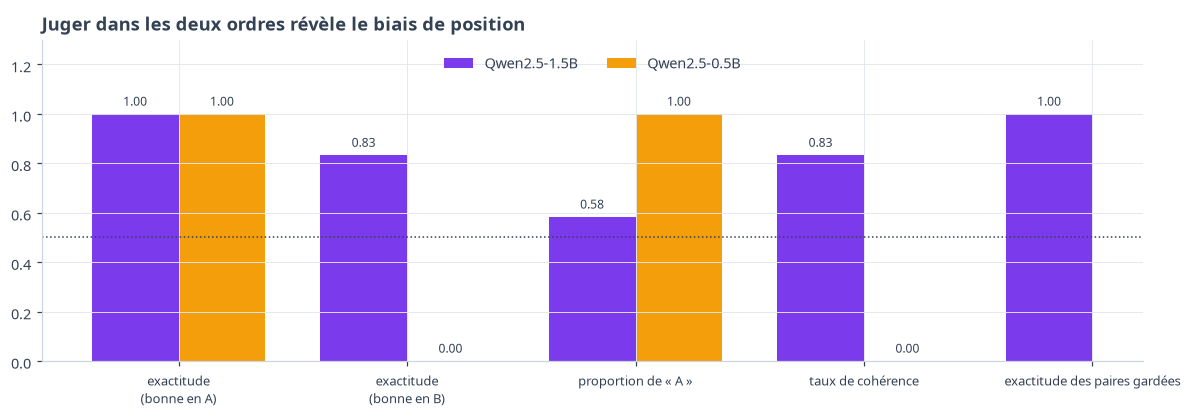

In [6]:
fig, ax = plt.subplots(figsize=(11, 3.9))
cols = list(synthese.columns)
xs = np.arange(len(cols))
for i, (nom, c) in enumerate(zip(synthese.index, [VIOLET, AMBER])):
    ax.bar(xs + (i - 0.5) * 0.38, synthese.loc[nom].values, 0.38, color=c, label=nom)
annotate_bars(ax, "{:.2f}", fontsize=8)
ax.axhline(0.5, color=SLATE, ls=":", lw=1)
ax.set_xticks(xs, [c.replace(" (", "\n(") for c in cols], fontsize=8.5)
ax.set_ylim(0, 1.3)
ax.set_title("Juger dans les deux ordres révèle le biais de position")
ax.legend(loc="upper center", ncol=2)
finish(fig)
plt.show()

**Solution et interprétation.**

- Un juge **sans biais** aurait la même exactitude quelle que soit la position de la
  bonne réponse, et choisirait « A » une fois sur deux en moyenne (les bonnes réponses
  étant placées autant en A qu'en B). Un écart entre les deux exactitudes, ou une
  proportion de « A » éloignée de 0,5, trahit un biais de position. Le modèle 0,5B y est
  bien plus sensible que le 1,5B : dans notre exécution, il répond « A » presque
  systématiquement, c'est-à-dire qu'il choisit par position et non par contenu ; le
  filtre de cohérence ne lui laisse alors (quasiment) aucune paire, d'où une valeur
  éventuellement manquante pour « exactitude des paires gardées ».
- Le **filtre de cohérence** ne garde que les paires où le juge désigne le même gagnant
  dans les deux ordres. Les paires gardées sont nettement plus fiables (leur exactitude
  dépasse celle de chaque ordre pris seul), au prix d'une perte de données d'autant plus
  forte que le juge est biaisé.
- Ce mini-lab a ses limites : 18 paires seulement, et des dégradations grossières. Sur de
  vraies paires de réponses de qualité voisine, les juges sont bien moins sûrs, et le
  biais de position pèse davantage.

> **À retenir.** Un juge IA a un biais de position, d'autant plus fort qu'il est petit.
> Poser la question dans les deux ordres et ne garder que les verdicts cohérents est une
> parade simple et efficace : on échange du volume contre de la fiabilité.

## Exercice 8.9 : Effondrement de modèle, calculs et remède

**Énoncé.** On reprend la chaîne gaussienne du cours 2 : à chaque génération, on tire
$n$ points du modèle courant et l'on réestime moyenne et écart-type par maximum de
vraisemblance.

1. Montrer que $\mathbb E[\sigma_t^2] = \sigma_0^2 \big((n-1)/n\big)^t$ et calculer la
   « demi-vie » de la variance moyenne pour $n = 50$.
2. On mélange à chaque génération une fraction $\rho$ de vraies données
   $\mathcal N(0, \sigma_0^2)$. En négligeant la dérive de la moyenne, établir la
   récurrence approchée de $\mathbb E[\sigma_t^2]$ et son point fixe. Application :
   $n = 50$, $\rho \in \{0{,}05 ; 0{,}1 ; 0{,}2 ; 0{,}5\}$. Vérifier par simulation.
3. Distribution catégorielle : un événement de probabilité $q$ disparaît d'une
   génération à l'autre si aucun des $n$ tirages ne le produit. Calculer cette
   probabilité pour $q = 10^{-3}$ et $q = 10^{-4}$, avec $n = 2\,000$.

**Rappels.** Cours 2, section 7 (section *Limitations to AI-generated data* du livre) :
l'effondrement de modèle fait disparaître les queues ; mélanger des données réelles
l'évite (Gerstgrasser et al., 2024), sans proportion universelle.

**Solution.**

1. Sachant $\sigma_t$, l'estimateur du maximum de vraisemblance vérifie
   $\mathbb E[\hat\sigma^2 \mid \sigma_t] = \frac{n-1}{n}\sigma_t^2$. Par l'espérance
   totale, $\mathbb E[\sigma_{t+1}^2] = \frac{n-1}{n}\mathbb E[\sigma_t^2]$, d'où la
   formule par récurrence. La demi-vie $t_{1/2}$ vérifie $((n-1)/n)^{t} = 1/2$ :
   $$t_{1/2} = \frac{\ln 2}{-\ln(1 - 1/n)} \approx n \ln 2 \approx 34{,}3 \text{ générations pour } n = 50.$$
2. Les données de la génération $t+1$ sont un mélange : une fraction $1-\rho$ de loi
   $\mathcal N(\mu_t, \sigma_t^2)$ et une fraction $\rho$ de loi $\mathcal N(0, \sigma_0^2)$.
   En négligeant l'écart des moyennes, la variance du mélange vaut
   $(1-\rho)\sigma_t^2 + \rho\sigma_0^2$, et l'estimation en prend une fraction
   $\frac{n-1}{n}$ en moyenne :
   $$v_{t+1} \approx \tfrac{n-1}{n}\big[(1-\rho) v_t + \rho \sigma_0^2\big]
   \quad\Rightarrow\quad v^\star = \frac{\frac{n-1}{n}\rho\,\sigma_0^2}{1 - \frac{n-1}{n}(1-\rho)}.$$
   Pour $n = 50$ et $\rho = 0{,}1$ : $v^\star = 0{,}098/0{,}118 \approx 0{,}83\,\sigma_0^2$.
   La variance ne s'effondre plus : elle se stabilise à un niveau d'autant plus proche de
   $\sigma_0^2$ que $\rho$ est grand.

In [7]:
n = 50
print(f"Demi-vie : {log(2) / -log(1 - 1 / n):.1f} générations (approximation n ln 2 = {n * log(2):.1f})")
rhos = [0.05, 0.1, 0.2, 0.5]
f = (n - 1) / n
theo = [f * r / (1 - f * (1 - r)) for r in rhos]
sim = []
for r in rhos:
    finals = [d8.gaussian_collapse(n, 400, r, seed=s)[1][200:] ** 2 for s in range(100)]
    sim.append(np.mean(finals))
pd.DataFrame({"ρ (part de réel)": rhos, "point fixe théorique v*/σ0²": theo,
              "simulation (moyenne, gén. 200-400)": sim}).round(3)

Demi-vie : 34.3 générations (approximation n ln 2 = 34.7)


,ρ (part de réel),point fixe théorique v*/σ0²,"simulation (moyenne, gén. 200-400)"
0,0.05,0.710,0.791
1,0.10,0.831,0.905
2,0.20,0.907,0.947
3,0.50,0.961,0.973


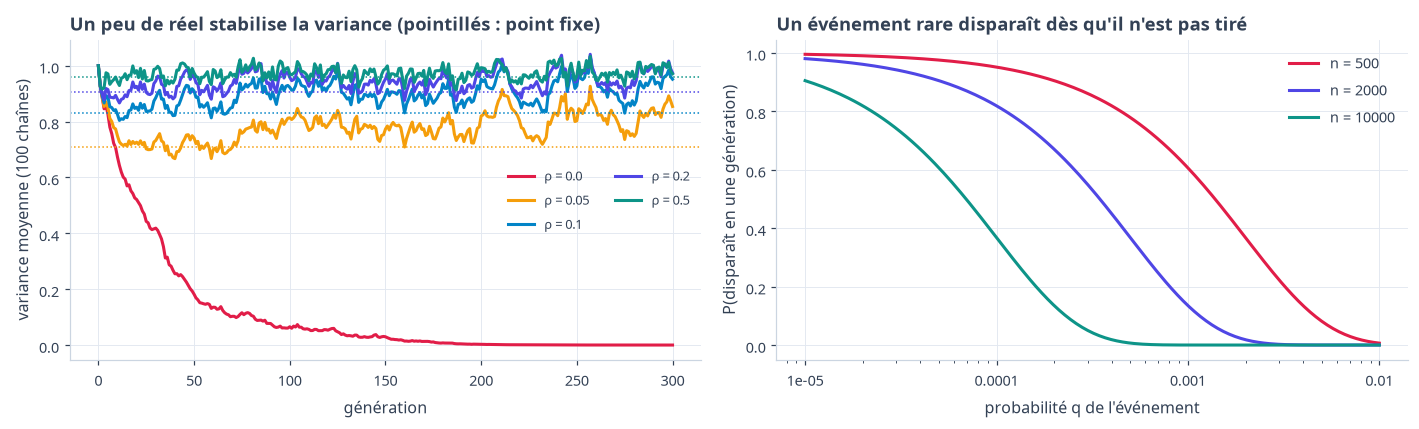

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
for r, c in zip([0.0] + rhos, [ROSE, AMBER, SKY, INDIGO, TEAL]):
    m = np.mean([d8.gaussian_collapse(n, 300, r, seed=s)[1] ** 2 for s in range(100)], axis=0)
    ax.plot(m, color=c, label=f"ρ = {r}")
    if r > 0:
        ax.axhline(f * r / (1 - f * (1 - r)), color=c, ls=":", lw=1)
ax.set_xlabel("génération")
ax.set_ylabel("variance moyenne (100 chaînes)")
ax.set_title("Un peu de réel stabilise la variance (pointillés : point fixe)")
ax.legend(loc="center right", ncol=2, fontsize=8.5)
ax = axes[1]
qs = np.logspace(-5, -2, 200)
for n_, c in zip([500, 2000, 10000], [ROSE, INDIGO, TEAL]):
    ax.plot(qs, (1 - qs) ** n_, color=c, label=f"n = {n_}")
ax.set_xscale("log")
log_lisible(ax, "x")
ax.set_xlabel("probabilité q de l'événement")
ax.set_ylabel("P(disparaît en une génération)")
ax.set_title("Un événement rare disparaît dès qu'il n'est pas tiré")
ax.legend(loc="upper right")
finish(fig)
plt.show()

**Vérification (question 2).** La simulation se stabilise bien, un peu au-dessus des
points fixes théoriques (de quelques pour cent à une dizaine de pour cent pour les
petits $\rho$) : le calcul néglige l'écart entre la moyenne du modèle $\mu_t$ et celle des
données réelles, qui ajoute un terme $\rho(1-\rho)\mu_t^2$ à la variance du mélange.
L'essentiel est confirmé : la variance ne s'effondre plus.

**Question 3.** $P(\text{disparition}) = (1-q)^n \approx e^{-nq}$ :

- $q = 10^{-3}$, $n = 2\,000$ : $e^{-2} \approx 0{,}135$. L'événement a 13,5 % de risque de
  disparaître à chaque génération ; sur 10 générations, la probabilité qu'il survive
  (sans données réelles) est d'environ $(1 - 0{,}135)^{10} \approx 0{,}23$, et même
  moins car sa fréquence estimée fluctue et peut baisser ;
- $q = 10^{-4}$ : $e^{-0{,}2} \approx 0{,}82$. L'événement disparaît presque sûrement dès la
  première génération.

Le seuil est $q \approx 1/n$ : tout événement plus rare que l'inverse de la taille de
l'échantillon généré est en danger. C'est exactement la queue de distribution (maladies
rares, cas limites) dont on a le plus besoin.

> **À retenir.** Sans données réelles, la variance moyenne décroît géométriquement
> (demi-vie $\approx n \ln 2$ générations) et tout événement de probabilité inférieure
> à $1/n$ disparaît vite. Une fraction $\rho$ de réel crée un point fixe
> $v^\star = \frac{f\rho}{1 - f(1-\rho)}\sigma_0^2$ avec $f = (n-1)/n$.